In [54]:
import sys
sys.path.append("..")

from pathlib import Path
EMB_DIR = Path("../project2")                  
results_folder = Path("../results/project2")   
results_folder.mkdir(parents=True, exist_ok=True)

from project1.data import load_data, EMOTIONS
from collections import Counter, OrderedDict
import part1, part2
from project1 import encoders, experiments
import numpy as np
import nltk
from tabulate import tabulate
from collections import OrderedDict
from urllib.request import urlopen
import shutil
import torch
from project2 import embeddings
import re


## Loading Data

In [55]:
# loading data and print data info

dataset, outcome_space = load_data(test_size=0.2, seed=0)

train_texts  = dataset["train"]["text"]
train_labels = dataset["train"]["label"]
pairs  = list(zip(train_texts, train_labels))   

print(dataset)                              
print("example sentence:" , dataset["train"][0])                   
print("class id and their counts:", Counter(dataset["train"]["label"]))   
print("outcome space:", [outcome_space.name(i) for i in range(len(EMOTIONS))]) 
print("first 20 (text, label) pairs:", pairs[0:20])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 6012
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1504
    })
})
example sentence: {'text': 'Grovelling people.', 'label': 4}
class id and their counts: Counter({0: 877, 1: 868, 5: 863, 3: 858, 6: 853, 2: 848, 4: 845})
outcome space: ['joy', 'fear', 'anger', 'sadness', 'disgust', 'shame', 'guilt']
first 20 (text, label) pairs: [('Grovelling people.', 4), ('My sweatheart were away on a trip, and then she got problems.', 3), ('When a close friend, residing in the hostel, lost his father I  \nreally pittied him and the situation made me feel sad.', 3), ('Receiving a postcard form my sweetheart who was abroad on  \nvacation, not being at all sure if he would write me or not.', 0), ('When my father made my mother go through really terrible  \nsituations, I felt furious, impotent, nervous, upset, ........', 2), ('When I realized that I was far behind the others in th

In [56]:

# NLTK needs these for word_tokenize and the stopword list (downloaded only once)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

# full GloVe table (as in the tutorial): for exploring the embedding space
trained_emb_model = part2.clslib.PretrainedEmbeddings(str(embeddings.download("glove50")), 50)

# small table with only the words in ISEAR (train + test): for training, same results but much faster
all_texts = list(dataset["train"]["text"]) + list(dataset["test"]["text"])
keep_words = set()
for tok in [part2.clslib.BasicTokenizer(True, True, True), part2.clslib.BasicTokenizer(True, False, False)]:
    for text in all_texts:
        keep_words.update(tok.tokens(text))

# add the parts with hyphens: 'girl-friend' etc.
# because the hyphens didnt remain for the rnn
keep_words |= {part for w in list(keep_words) for part in w.split("-")}   
isear_emb_model = embeddings.load("glove50", keep_words)

# tutorial cell
print("Shape of embedding matrix:", trained_emb_model.vectors.shape)
print("Size of vocabulary:", len(trained_emb_model.vocab))
print(f"UNK token {trained_emb_model.vocab.default_index}:{trained_emb_model.vocab.default_word}")
print(f"PAD token {trained_emb_model.vocab.index(trained_emb_model.pad_token)}:{trained_emb_model.pad_token}")
print("ISEAR table:", isear_emb_model.vectors.shape)

for word in outcome_space:
    print(word, word in trained_emb_model, trained_emb_model.index(word), trained_emb_model.embed_word(word).shape)

Shape of embedding matrix: (1287615, 50)
Size of vocabulary: 1287615
UNK token 1:<unk>
PAD token 0:<pad>
ISEAR table: (8701, 50)
joy True 5927 (50,)
fear True 1680 (50,)
anger True 3996 (50,)
sadness True 13701 (50,)
disgust True 18845 (50,)
shame True 8182 (50,)
guilt True 8974 (50,)


## Build tokenizer for bow and rnn

Daarnaast checken we wat de coverage is (percentage woorden in onze dataset in het embedding model staan). Hoe meer er niet in staan -> hoe meer \<unk\> tekens

In [57]:
class HyphenSplitTokenizer(part2.clslib.BasicTokenizer):
    """BasicTokenizer that first splits hyphenated words ('girl-friend' -> 'girl friend'),
    because GloVe has vectors for the parts but not for most hyphenated forms."""
    def tokens(self, text):
        return super().tokens(re.sub(r"(?<=\w)-(?=\w)", " ", text))

# for embed-and-pool: punctuation and stopwords add nothing useful to an average, so drop them
tokenizer_for_bow = part2.clslib.BasicTokenizer(
    lowercase=True, remove_punct=True, remove_stopwords=True,
    language='english', vocab=isear_emb_model.vocab
)

# for the LSTM: keep everything (word order and function words can matter), but split hyphenated words
tokenizer_for_rnn = HyphenSplitTokenizer(
    lowercase=True, remove_punct=False, remove_stopwords=False,
    language='english', vocab=isear_emb_model.vocab
)

In [58]:
# Met claude even gecheckt of de embedding een goede coverage heeft -> 
# komen alle tokens wel voor in de embedding of is er veel unk
# vraag in project: Does the model's vocabulary give enough coverage to the words in your texts? etc.

#  Coverage: how many of our tokens have a GloVe vector?
# token coverage = share of all running tokens that are in GloVe (frequent words count more often)
# type coverage  = share of distinct words that are in GloVe (every word counts once)
# Tokens without a vector become <unk>, so their information is lost.

def coverage(texts, tokenizer, emb_model):
    counts = Counter(tok for text in texts for tok in tokenizer.tokens(text))
    oov = Counter({tok: n for tok, n in counts.items() if tok not in emb_model})   # OOV = out of vocabulary
    n_tokens = sum(counts.values())
    stats = {
        "tokens": n_tokens,
        "token coverage": 1 - sum(oov.values()) / n_tokens,
        "types": len(counts),
        "type coverage": 1 - len(oov) / len(counts),
    }
    return stats, oov

for name, tok in [("bow", tokenizer_for_bow), ("rnn", tokenizer_for_rnn)]:
    stats, oov = coverage(train_texts, tok, trained_emb_model)
    print(f"--- {name} tokenizer")
    for key, value in stats.items():
        print(f"  {key:15s} {value:.4f}" if isinstance(value, float) else f"  {key:15s} {value}")
    print(f"  {len(oov)} OOV types, most frequent:")
    print("  ", oov.most_common(30))

--- bow tokenizer
  tokens          59438
  token coverage  0.9929
  types           7969
  type coverage   0.9552
  357 OOV types, most frequent:
   [('examn', 33), ('fianct', 10), ('quarelled', 5), ('assulted', 4), ('fuvest', 3), ('rejoyced', 3), ('cardriver', 2), ('fiancte', 2), ('lazyness', 2), ('maryhuana', 2), ('examns', 2), ('nieghbour', 2), ('lingadzi', 2), ('schhol', 2), ('workshift', 2), ('nitht', 2), ('peolpe', 2), ('misleaded', 2), ('accquaintances', 2), ('gradmother', 2), ('pittied', 1), ('bophal', 1), ('ambulants', 1), ('permisssion', 1), ('cherised', 1), ('unconsiderate', 1), ('pacience', 1), ('putridness', 1), ('whash', 1), ('unconscienciously', 1)]
--- rnn tokenizer
  tokens          148144
  token coverage  0.9966
  types           8240
  type coverage   0.9475
  433 OOV types, most frequent:
   [('examn', 33), ('fianct', 9), ('quarelled', 5), ('assulted', 4), ('fuvest', 3), ('rejoyced', 3), ('u.g.c', 3), ('m.s.c', 3), ('n.z', 3), ('cardriver', 2), ('7.', 2), ('fianct

In [59]:
def cos_similarity(u, v):
    """Cosine similarity of two vectors: 1 = same direction, 0 = unrelated, -1 = opposite."""
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))

def topk_ids(v, E, k=10):
    """Row ids of the k rows of E with the highest cosine similarity to v."""
    sims = (E @ v) / (np.linalg.norm(E, axis=1) * np.linalg.norm(v) + 1e-12)
    return np.argsort(-sims)[:k]


emb = trained_emb_model
emotions = ["joy", "fear", "anger", "sadness", "disgust", "shame", "guilt"]

# 1. How similar are the seven labels to each other?
table = [[e1] + [cos_similarity(emb.embed_word(e1), emb.embed_word(e2)) for e2 in emotions] for e1 in emotions]
print(tabulate(table, headers=[""] + emotions, floatfmt=".2f"))

# 2. Nearest neighbours of emotion adjectives.
# We only search the 100k most frequent words (the file is sorted by frequency), skipping <pad> and <unk>:
# the full 1.3M vocabulary is full of rare junk words that would clutter the lists.
E = emb.vectors[2:100_002]
print()
for word in ["happy", "afraid", "angry", "sad", "disgusted", "ashamed", "guilty"]:
    ids = topk_ids(emb.embed_word(word), E, k=11) + 2      # +2: shift back to row ids in the full matrix
    print(f"{word:10s}", ", ".join(emb.word(i) for i in ids if emb.word(i) != word))

           joy    fear    anger    sadness    disgust    shame    guilt
-------  -----  ------  -------  ---------  ---------  -------  -------
joy       1.00    0.53     0.64       0.78       0.60     0.70     0.53
fear      0.53    1.00     0.87       0.61       0.67     0.76     0.69
anger     0.64    0.87     1.00       0.76       0.85     0.72     0.68
sadness   0.78    0.61     0.76       1.00       0.79     0.75     0.69
disgust   0.60    0.67     0.85       0.79       1.00     0.78     0.65
shame     0.70    0.76     0.72       0.75       0.78     1.00     0.74
guilt     0.53    0.69     0.68       0.69       0.65     0.74     1.00

happy      'm, everyone, really, always, everybody, definitely, me, 'd, something, maybe
afraid     scared, anybody, nobody, everyone, anymore, know, pretend, anyone, wanting, tell
angry      enraged, furious, outraged, heard, anger, angered, cries, outrage, frustrated, frightened
sad        awful, sorry, feeling, horrible, terrible, feels, sadly, t

In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# same seeds and folds as project 1, so results are directly comparable
my_seeds = [0, 1, 2]
num_folds = 5
my_cross_validation_sets = [
    part1.experiment.cross_validation_split(pairs=pairs, k=num_folds, seed=seed) for seed in my_seeds
]

print("device:", DEVICE)
print("fold sizes:", len(my_cross_validation_sets[0][0]["training"]), "train /", len(my_cross_validation_sets[0][0]["validation"]), "validation")

device: cpu
fold sizes: 4809 train / 1203 validation


## Test (1 fold)

Quick experiment on 1 fold to show insights into embed-and-pool (bow) and lstm 

In [61]:
# Smoke test: train one embed-and-pool model on fold 0 (tutorial settings)
metrics, best_epoch = part2.experiment.train(
    my_cross_validation_sets[0][0]['training'],
    my_cross_validation_sets[0][0]['validation'],
    tokenizer_for_bow,
    isear_emb_model,
    num_classes=len(outcome_space),
    save_to=str(results_folder / "tmp-bow"),
    enc_type='embed-and-pool',
    enc_kwargs={'freeze_embeddings': True},
    regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1},
    opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 20},
    device=DEVICE,
)
print(f"Best epoch: {best_epoch}")
print(f"Train accuracy: {metrics[best_epoch]['train_metrics']['accuracy']:.4f}")
print(f"Validation accuracy: {metrics[best_epoch]['val_metrics']['accuracy']:.4f}")

Tokenizing texts...
Tokenization done! Time taken: 0.530 seconds
Dataloader done! Time taken: 0.048 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8776 | train acc: 0.2599 | val loss: 1.7749 | val acc: 0.3167
Epoch 02 | train loss: 1.7113 | train acc: 0.3419 | val loss: 1.6364 | val acc: 0.3633
Epoch 03 | train loss: 1.6423 | train acc: 0.3589 | val loss: 1.5898 | val acc: 0.3998
Epoch 04 | train loss: 1.6089 | train acc: 0.3805 | val loss: 1.5636 | val acc: 0.4048
Epoch 05 | train loss: 1.6113 | train acc: 0.3830 | val loss: 1.5563 | val acc: 0.4190
Epoch 06 | train loss: 1.5916 | train acc: 0.3901 | val loss: 1.5463 | val acc: 0.4140
Epoch 07 | train loss: 1.5832 | train acc: 0.3957 | val loss: 1.5373 | val acc: 0.4190
Epoch 08 | train loss: 1.5814 | train acc: 0.4011 | val loss: 1.5370 | val acc: 0.4273
Epoch 09 | train loss: 1.5814 | train acc: 0.3886 | val loss: 1.5300 | val acc: 0.4181
Epoch 10 | train loss: 1.5800 | train acc: 0.3988 | val loss: 1.5292 | val acc: 0.4239
Epoch 11 | train loss: 1.5698 | train acc: 0.4026 | val loss: 1.5277 | val acc: 0.4190
Epoch 12 | train loss: 1.5751 | train acc: 

In [62]:
# Smoke test: train one LSTM model on fold 0 (tutorial settings; a few minutes on CPU)
metrics, best_epoch = part2.experiment.train(
    my_cross_validation_sets[0][0]['training'],
    my_cross_validation_sets[0][0]['validation'],
    tokenizer_for_rnn,
    isear_emb_model,
    num_classes=len(outcome_space),
    save_to=str(results_folder / "tmp-lstm"),
    enc_type='lstm',
    enc_kwargs={'freeze_embeddings': True, 'hidden_size': 20, 'word_dropout': 0.1},
    regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1},
    opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 20, 'num_epochs': 20},
    device=DEVICE,
)
print(f"Best epoch: {best_epoch}")
print(f"Train accuracy: {metrics[best_epoch]['train_metrics']['accuracy']:.4f}")
print(f"Validation accuracy: {metrics[best_epoch]['val_metrics']['accuracy']:.4f}")

Tokenizing texts...
Tokenization done! Time taken: 0.732 seconds
Dataloader done! Time taken: 0.019 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9124 | train acc: 0.1969 | val loss: 1.7996 | val acc: 0.2610
Epoch 02 | train loss: 1.7728 | train acc: 0.2868 | val loss: 1.6587 | val acc: 0.3425
Epoch 03 | train loss: 1.6821 | train acc: 0.3464 | val loss: 1.5959 | val acc: 0.3882
Epoch 04 | train loss: 1.6273 | train acc: 0.3747 | val loss: 1.5430 | val acc: 0.4156
Epoch 05 | train loss: 1.5685 | train acc: 0.4003 | val loss: 1.5263 | val acc: 0.4264
Epoch 06 | train loss: 1.5280 | train acc: 0.4188 | val loss: 1.5694 | val acc: 0.4065
Epoch 07 | train loss: 1.5097 | train acc: 0.4344 | val loss: 1.4808 | val acc: 0.4264
Epoch 08 | train loss: 1.4647 | train acc: 0.4465 | val loss: 1.4607 | val acc: 0.4472
Epoch 09 | train loss: 1.4331 | train acc: 0.4662 | val loss: 1.4528 | val acc: 0.4389
Epoch 10 | train loss: 1.4318 | train acc: 0.4635 | val loss: 1.4248 | val acc: 0.4722
Epoch 11 | train loss: 1.3879 | train acc: 0.4814 | val loss: 1.3990 | val acc: 0.4780
Epoch 12 | train loss: 1.3753 | train acc: 

## Training Embed-and-pool

In [63]:
# Baseline: tutorial settings, 3 seeds x 5 folds (same folds as project 1)
my_classifiers = OrderedDict()

my_classifiers['embed-and-pool'] = []
for run, seed in enumerate(my_seeds):   # ~5 minutes on CPU for all seeds
    my_classifiers['embed-and-pool'].append(
        part2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_bow,
            emb_model=isear_emb_model,
            enc_type='embed-and-pool',
            enc_kwargs={'freeze_embeddings': True},
            regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.5},
            opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 20},
            device=DEVICE,
            save_to=f"{results_folder}/embed-and-pool/seed-{seed}",
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 0.528 seconds
Dataloader done! Time taken: 0.020 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9493 | train acc: 0.1587 | val loss: 1.8974 | val acc: 0.2918
Epoch 02 | train loss: 1.9008 | train acc: 0.2142 | val loss: 1.8265 | val acc: 0.3250
Epoch 03 | train loss: 1.8473 | train acc: 0.2585 | val loss: 1.7516 | val acc: 0.3558
Epoch 04 | train loss: 1.8043 | train acc: 0.2834 | val loss: 1.7022 | val acc: 0.3832
Epoch 05 | train loss: 1.7808 | train acc: 0.2907 | val loss: 1.6717 | val acc: 0.3815
Epoch 06 | train loss: 1.7714 | train acc: 0.2999 | val loss: 1.6524 | val acc: 0.3890
Epoch 07 | train loss: 1.7610 | train acc: 0.3132 | val loss: 1.6436 | val acc: 0.3857
Epoch 08 | train loss: 1.7618 | train acc: 0.3136 | val loss: 1.6397 | val acc: 0.4007
Epoch 09 | train loss: 1.7635 | train acc: 0.3063 | val loss: 1.6435 | val acc: 0.3990
Epoch 10 | train loss: 1.7423 | train acc: 0.3192 | val loss: 1.6348 | val acc: 0.3965
Epoch 11 | train loss: 1.7630 | train acc: 0.3092 | val loss: 1.6338 | val acc: 0.3924
Epoch 12 | train loss: 1.7511 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9395 | train acc: 0.1772 | val loss: 1.9029 | val acc: 0.2535
Epoch 02 | train loss: 1.8948 | train acc: 0.2265 | val loss: 1.8353 | val acc: 0.3142
Epoch 03 | train loss: 1.8404 | train acc: 0.2722 | val loss: 1.7618 | val acc: 0.3383
Epoch 04 | train loss: 1.8047 | train acc: 0.2816 | val loss: 1.7213 | val acc: 0.3416
Epoch 05 | train loss: 1.7813 | train acc: 0.2920 | val loss: 1.7000 | val acc: 0.3533
Epoch 06 | train loss: 1.7806 | train acc: 0.2899 | val loss: 1.6868 | val acc: 0.3516
Epoch 07 | train loss: 1.7645 | train acc: 0.3003 | val loss: 1.6729 | val acc: 0.3608
Epoch 08 | train loss: 1.7722 | train acc: 0.3073 | val loss: 1.6711 | val acc: 0.3608
Epoch 09 | train loss: 1.7470 | train acc: 0.3159 | val loss: 1.6621 | val acc: 0.3624
Epoch 10 | train loss: 1.7435 | train acc: 0.3117 | val loss: 1.6537 | val acc: 0.3749
Epoch 11 | train loss: 1.7517 | train acc: 0.3119 | val loss: 1.6589 | val acc: 0.3757
Epoch 12 | train loss: 1.7429 | train acc: 

... (26 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9357 | train acc: 0.1790 | val loss: 1.8896 | val acc: 0.3078
Epoch 02 | train loss: 1.8906 | train acc: 0.2266 | val loss: 1.8189 | val acc: 0.3153
Epoch 03 | train loss: 1.8266 | train acc: 0.2773 | val loss: 1.7495 | val acc: 0.3527
Epoch 04 | train loss: 1.7927 | train acc: 0.2900 | val loss: 1.7111 | val acc: 0.3469
Epoch 05 | train loss: 1.7729 | train acc: 0.2979 | val loss: 1.6883 | val acc: 0.3511
Epoch 06 | train loss: 1.7643 | train acc: 0.3044 | val loss: 1.6710 | val acc: 0.3710
Epoch 07 | train loss: 1.7481 | train acc: 0.3168 | val loss: 1.6620 | val acc: 0.3661
Epoch 08 | train loss: 1.7434 | train acc: 0.3175 | val loss: 1.6557 | val acc: 0.3735
Epoch 09 | train loss: 1.7421 | train acc: 0.3166 | val loss: 1.6561 | val acc: 0.3569
Epoch 10 | train loss: 1.7545 | train acc: 0.3170 | val loss: 1.6545 | val acc: 0.3669
Epoch 11 | train loss: 1.7443 | train acc: 0.3146 | val loss: 1.6484 | val acc: 0.3744
Epoch 12 | train loss: 1.7368 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9431 | train acc: 0.1642 | val loss: 1.8962 | val acc: 0.3120
Epoch 02 | train loss: 1.8950 | train acc: 0.2218 | val loss: 1.8195 | val acc: 0.3627
Epoch 03 | train loss: 1.8423 | train acc: 0.2649 | val loss: 1.7426 | val acc: 0.3619
Epoch 04 | train loss: 1.8039 | train acc: 0.2863 | val loss: 1.6983 | val acc: 0.3852
Epoch 05 | train loss: 1.7796 | train acc: 0.3021 | val loss: 1.6711 | val acc: 0.3819
Epoch 06 | train loss: 1.7809 | train acc: 0.3037 | val loss: 1.6597 | val acc: 0.3910
Epoch 07 | train loss: 1.7630 | train acc: 0.2994 | val loss: 1.6494 | val acc: 0.3777
Epoch 08 | train loss: 1.7646 | train acc: 0.3119 | val loss: 1.6442 | val acc: 0.3852
Epoch 09 | train loss: 1.7554 | train acc: 0.3098 | val loss: 1.6347 | val acc: 0.3877
Epoch 10 | train loss: 1.7612 | train acc: 0.3025 | val loss: 1.6381 | val acc: 0.3902
Epoch 11 | train loss: 1.7622 | train acc: 0.3098 | val loss: 1.6341 | val acc: 0.3885
Epoch 12 | train loss: 1.7503 | train acc: 

## Training LSTM

In [64]:
my_classifiers['lstm'] = []
for run, seed in enumerate(my_seeds):   # ~15-20 minutes on CPU for all seeds
    my_classifiers['lstm'].append(
        part2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_rnn,
            emb_model=isear_emb_model,
            enc_type='lstm',
            enc_kwargs={'freeze_embeddings': True, 'hidden_size': 20, 'word_dropout': 0.},
            regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1},
            opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 20},
            device=DEVICE,
            save_to=f"{results_folder}/lstm/seed-{seed}",
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 0.764 seconds
Dataloader done! Time taken: 0.021 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9469 | train acc: 0.1518 | val loss: 1.9395 | val acc: 0.2095
Epoch 02 | train loss: 1.8974 | train acc: 0.2287 | val loss: 1.8467 | val acc: 0.2419
Epoch 03 | train loss: 1.7901 | train acc: 0.2797 | val loss: 1.7140 | val acc: 0.3209
Epoch 04 | train loss: 1.6746 | train acc: 0.3431 | val loss: 1.6134 | val acc: 0.3666
Epoch 05 | train loss: 1.5960 | train acc: 0.3780 | val loss: 1.5874 | val acc: 0.3849
Epoch 06 | train loss: 1.5516 | train acc: 0.4034 | val loss: 1.5448 | val acc: 0.3998
Epoch 07 | train loss: 1.5080 | train acc: 0.4217 | val loss: 1.5321 | val acc: 0.4165
Epoch 08 | train loss: 1.4837 | train acc: 0.4383 | val loss: 1.4948 | val acc: 0.4356
Epoch 09 | train loss: 1.4592 | train acc: 0.4435 | val loss: 1.4939 | val acc: 0.4339
Epoch 10 | train loss: 1.4318 | train acc: 0.4519 | val loss: 1.4954 | val acc: 0.4364
Epoch 11 | train loss: 1.4093 | train acc: 0.4621 | val loss: 1.4617 | val acc: 0.4580
Epoch 12 | train loss: 1.3879 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9347 | train acc: 0.1732 | val loss: 1.9085 | val acc: 0.1845
Epoch 02 | train loss: 1.8639 | train acc: 0.2396 | val loss: 1.7807 | val acc: 0.2959
Epoch 03 | train loss: 1.7478 | train acc: 0.3086 | val loss: 1.6900 | val acc: 0.3292
Epoch 04 | train loss: 1.6594 | train acc: 0.3446 | val loss: 1.6579 | val acc: 0.3608
Epoch 05 | train loss: 1.6017 | train acc: 0.3683 | val loss: 1.6159 | val acc: 0.3608
Epoch 06 | train loss: 1.5639 | train acc: 0.3905 | val loss: 1.5899 | val acc: 0.3774
Epoch 07 | train loss: 1.5459 | train acc: 0.4020 | val loss: 1.5797 | val acc: 0.3699
Epoch 08 | train loss: 1.5118 | train acc: 0.4159 | val loss: 1.5662 | val acc: 0.3807
Epoch 09 | train loss: 1.4947 | train acc: 0.4203 | val loss: 1.5530 | val acc: 0.3882
Epoch 10 | train loss: 1.4758 | train acc: 0.4309 | val loss: 1.5447 | val acc: 0.3874
Epoch 11 | train loss: 1.4653 | train acc: 0.4302 | val loss: 1.5446 | val acc: 0.3998
Epoch 12 | train loss: 1.4352 | train acc: 

... (26 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9396 | train acc: 0.1661 | val loss: 1.9031 | val acc: 0.2271
Epoch 02 | train loss: 1.8401 | train acc: 0.2524 | val loss: 1.7693 | val acc: 0.3070
Epoch 03 | train loss: 1.7337 | train acc: 0.3033 | val loss: 1.6698 | val acc: 0.3486
Epoch 04 | train loss: 1.6586 | train acc: 0.3443 | val loss: 1.6278 | val acc: 0.3419
Epoch 05 | train loss: 1.6003 | train acc: 0.3753 | val loss: 1.6155 | val acc: 0.3835
Epoch 06 | train loss: 1.5755 | train acc: 0.3721 | val loss: 1.5746 | val acc: 0.3910
Epoch 07 | train loss: 1.5576 | train acc: 0.3917 | val loss: 1.5738 | val acc: 0.3794
Epoch 08 | train loss: 1.5197 | train acc: 0.4091 | val loss: 1.5732 | val acc: 0.3910
Epoch 09 | train loss: 1.4955 | train acc: 0.4164 | val loss: 1.5372 | val acc: 0.3977
Epoch 10 | train loss: 1.4841 | train acc: 0.4214 | val loss: 1.5324 | val acc: 0.4110
Epoch 11 | train loss: 1.4631 | train acc: 0.4337 | val loss: 1.5567 | val acc: 0.4018
Epoch 12 | train loss: 1.4490 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9411 | train acc: 0.1661 | val loss: 1.9024 | val acc: 0.2346
Epoch 02 | train loss: 1.8335 | train acc: 0.2538 | val loss: 1.7629 | val acc: 0.2854
Epoch 03 | train loss: 1.7338 | train acc: 0.3100 | val loss: 1.6544 | val acc: 0.3394
Epoch 04 | train loss: 1.6553 | train acc: 0.3407 | val loss: 1.6045 | val acc: 0.3602
Epoch 05 | train loss: 1.6145 | train acc: 0.3613 | val loss: 1.5784 | val acc: 0.3735
Epoch 06 | train loss: 1.5905 | train acc: 0.3825 | val loss: 1.5516 | val acc: 0.3918
Epoch 07 | train loss: 1.5548 | train acc: 0.3875 | val loss: 1.5461 | val acc: 0.3885
Epoch 08 | train loss: 1.5404 | train acc: 0.4006 | val loss: 1.5333 | val acc: 0.4010
Epoch 09 | train loss: 1.5077 | train acc: 0.4216 | val loss: 1.5023 | val acc: 0.4151
Epoch 10 | train loss: 1.4895 | train acc: 0.4177 | val loss: 1.4980 | val acc: 0.4043
Epoch 11 | train loss: 1.4632 | train acc: 0.4347 | val loss: 1.4900 | val acc: 0.4043
Epoch 12 | train loss: 1.4617 | train acc: 

## Analysis

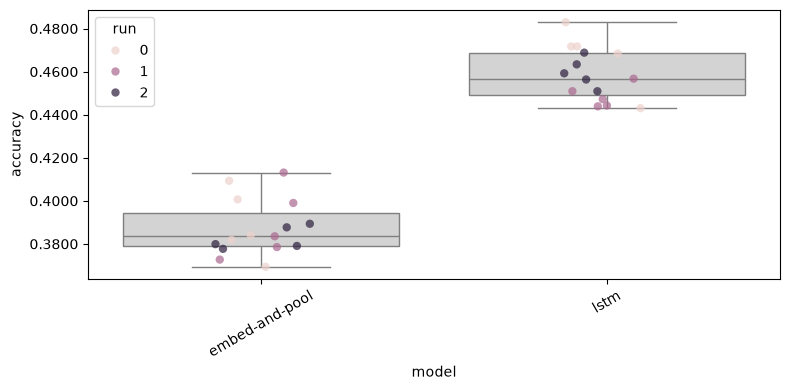

embed-and-pool  mean=0.3871  std=0.0125  (n=15)
lstm            mean=0.4586  std=0.0118  (n=15)


In [65]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

for name, runs in my_classifiers.items():
    accs = np.array([list(run['accuracies'].values()) for run in runs])   # shape [seeds, folds]
    print(f"{name:15s} mean={accs.mean():.4f}  std={accs.std():.4f}  (n={accs.size})")